# 📊 Telco Customer Churn: Compararea Performanței între Regresia Logistică, Random Forest și XGBoost

## 📝 Descrierea Proiectului
Acest proiect implementază un flux complet de Machine Learning (end-to-end pipeline) având ca obiectiv principal analiza comparativă a performanței și optimizarea modelelor de clasificare binară: Regresia Logistică, Random Forest (bazat pe Bagging) și XGBoost (bazat pe Boosting).

Folosind setul de date Telco Customer Churn, proiectul parcurge etapele de preprocesare, gestionare a datelor lipsă, scalare dedicată și reechilibrare avansată a claselor prin tehnica SMOTE. De asemenea, integrează GridSearchCV pentru căutarea celor mai buni hiperparametri și Threshold Tuning pe baza curbei Precision-Recall pentru a maximiza eficiența în identificarea clienților cu risc de a părăsi operatorul. Evaluarea se bazează pe metrici riguroase orientate spre clasa minoritară (F1-score, Precision, Recall și matrici de confuzie).
## 👤 Autor
* **Bogdan Panea**


**Pasul 1 - Explorarea datelor <br> Încărcăm setul de date și analizăm
distribuția clasei țintă și valorile lipsă ascunse. Facem acest lucru pentru a identifica din timp dezechilibrul claselor și problemele de curățare necesare.**

--- DIMENSIUNE SET DE DATE ---
Număr rânduri și coloane: (7043, 22)

Primele rânduri din setul de date (.head()):


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binar
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1



--- VALORI LIPSĂ / SPAȚII GOALE PE COLOANE ---
TotalCharges    11
dtype: int64

--- DISTRIBUȚIA ȚINTEI (Churn) ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Proporții:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


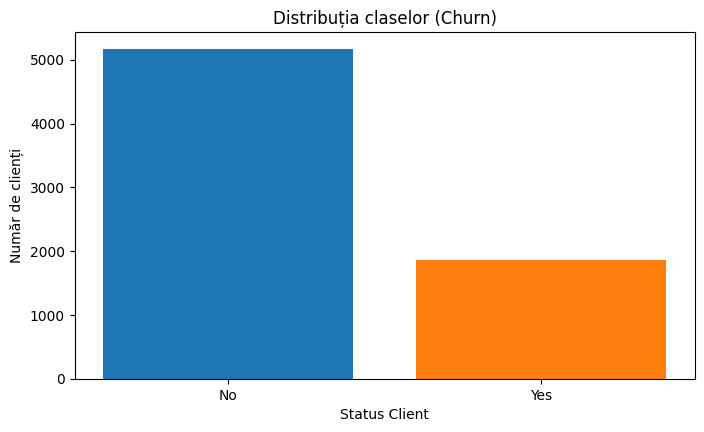

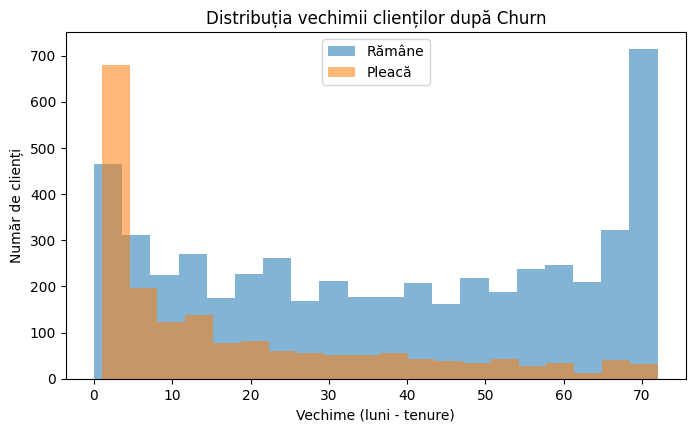

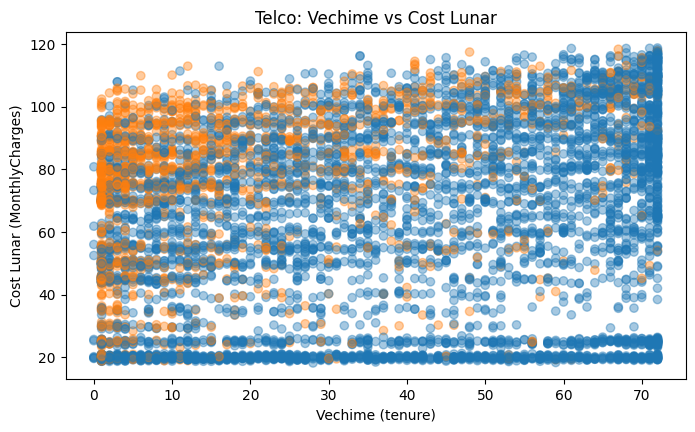

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)

# 1. Încărcare date
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(URL)
df_raw.columns = [c.strip() for c in df_raw.columns]

df = df_raw.copy()
df["Churn_binar"] = df["Churn"].map({"No": 0, "Yes": 1})

# A. Dimensiune și Head
print("--- DIMENSIUNE SET DE DATE ---")
print(f"Număr rânduri și coloane: {df.shape}")
print("\nPrimele rânduri din setul de date (.head()):")
display(df.head())

# B. Valori lipsă pe coloane
print("\n--- VALORI LIPSĂ / SPAȚII GOALE PE COLOANE ---")
valori_goale = (df == " ").sum()
print(valori_goale[valori_goale > 0])

# C. Distribuția coloanei de prezis
print("\n--- DISTRIBUȚIA ȚINTEI (Churn) ---")
print(df["Churn"].value_counts())
print("\nProporții:")
print(df["Churn"].value_counts(normalize=True).round(3))

# D. Cele 3 grafice cerute
# Grafic 1: Distribuția țintei
churn_counts = df["Churn"].value_counts()
plt.bar(churn_counts.index, churn_counts.values, color=["tab:blue", "tab:orange"])
plt.xlabel("Status Client")
plt.ylabel("Număr de clienți")
plt.title("Distribuția claselor (Churn)")
plt.show()

# Grafic 2: Vechimea (tenure) în funcție de Churn
for status, label, color in [("No", "Rămâne", "tab:blue"), ("Yes", "Pleacă", "tab:orange")]:
    subset = df[df["Churn"] == status]
    plt.hist(subset["tenure"], bins=20, alpha=0.55, label=label, color=color)

plt.xlabel("Vechime (luni - tenure)")
plt.ylabel("Număr de clienți")
plt.title("Distribuția vechimii clienților după Churn")
plt.legend()
plt.show()

# Grafic 3: Scatter plot (Vechime vs Cost Lunar)
colors = df["Churn_binar"].map({0: "tab:blue", 1: "tab:orange"})
plt.scatter(df["tenure"], df["MonthlyCharges"], c=colors, alpha=0.4)
plt.xlabel("Vechime (tenure)")
plt.ylabel("Cost Lunar (MonthlyCharges)")
plt.title("Telco: Vechime vs Cost Lunar")
plt.show()

**Pasul 2 - Preprocesarea datelor <br>
Curățăm valorile lipsă din TotalCharges și transformăm variabilele categorice în numere prin One-Hot Encoding, împărțind apoi datele în train și test. Nu aplicăm scalare deoarece folosim exclusiv algoritmi bazați pe arbori.**

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Tratarea valorilor lipsă (TotalCharges conține spații goale care devin NaN la conversie)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# 2. Transformarea coloanelor text (categorice) în numere
# Excludem ID-ul clientului și coloanele țintă
X = df.drop(columns=["customerID", "Churn", "Churn_binar"])
y = df["Churn_binar"]

# Folosim pd.get_dummies (One-Hot Encoding) pentru variabilele categorice
X = pd.get_dummies(X, drop_first=True)

# 3. Împărțire train / test (cu stratificare pe țintă pentru a păstra proporția de ~26% churn)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Scalare dedicată (necesară pentru Regresia Logistică)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiune set antrenament: {X_train.shape}")
print(f"Dimensiune set test: {X_test.shape}")
print(f"Valori lipsă rămase în setul de antrenament: {X_train.isna().sum().sum()}")


print("\n--- APLICARE SMOTE PE SETUL DE ANTRENAMENT ---")
print(f"Distribuția claselor ÎNAINTE de SMOTE:\n{pd.Series(y_train).value_counts()}")

# Aplicăm SMOTE EXCLUSIV pe datele de antrenament scalate
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"\nDistribuția claselor DUPĂ SMOTE:\n{pd.Series(y_train_resampled).value_counts()}")
print(f"Noua dimensiune a setului de antrenament: {X_train_resampled.shape}")

Dimensiune set antrenament: (5282, 30)
Dimensiune set test: (1761, 30)
Valori lipsă rămase în setul de antrenament: 0

--- APLICARE SMOTE PE SETUL DE ANTRENAMENT ---
Distribuția claselor ÎNAINTE de SMOTE:
Churn_binar
0    3880
1    1402
Name: count, dtype: int64

Distribuția claselor DUPĂ SMOTE:
Churn_binar
0    3880
1    3880
Name: count, dtype: int64
Noua dimensiune a setului de antrenament: (7760, 30)


**Pasul 3 - Modelul Baseline <br>
Construim un model de referință (DummyClassifier) bazat pe clasa majoritară pentru a stabili pragul minim de performanță. Orice model avansat trebuie să depășească clar acest baseline.**

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Creăm un DummyClassifier care ghicește mereu clasa majoritară ("most_frequent")
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)

# Antrenăm modelul (practic, doar reține clasa majoritară din setul de train)
dummy_clf.fit(X_train, y_train)

# Generăm predicții pe setul de test
y_pred_dummy = dummy_clf.predict(X_test)

# Evaluăm acuratețea
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
print(f"Acuratețea modelului Dummy (baseline): {dummy_accuracy:.4f}")

# Detalii suplimentare pentru a vedea cum se descurcă pe clase
print("\nRaport de clasificare pentru Baseline:")
print(classification_report(y_test, y_pred_dummy, zero_division=0))

Acuratețea modelului Dummy (baseline): 0.7348

Raport de clasificare pentru Baseline:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1294
           1       0.00      0.00      0.00       467

    accuracy                           0.73      1761
   macro avg       0.37      0.50      0.42      1761
weighted avg       0.54      0.73      0.62      1761



**Pasul 4 - Antrenare, Optimizare și Bonus (Modele multiple + Feature Importance)**

--- 4.1. Optimizare Regresie Logistică ---
Cei mai buni parametri Regresie Logistică: {'C': 0.01, 'solver': 'liblinear'}
F1-score Regresie Logistică optimizată: 0.5945

--- 4.2. Optimizare Random Forest ---
Cei mai buni parametri RF: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}
F1-score RF optimizat: 0.5595

--- 4.3. Optimizare XGBoost ---
Cei mai buni parametri XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
F1-score XGBoost optimizat: 0.5549

🏆 COMPARAȚIE FINALĂ & VERDICT (3 MODELE)
F1-score Regresie Logistică optimizată: 0.5945
F1-score Random Forest optimizat:       0.5595
F1-score XGBoost optimizat:             0.5549

=> VERDICT: Modelul câștigător este **Regresie Logistică** cu un F1-score de 0.5945.
🎯 6. OPTIMIZAREA PRAGULUI DE DECIZIE (Regresia Logistică)
Pragul implicit: 0.50 | F1-score inițial: 0.5945
Pragul optim găsit: 0.30 | F1-score optimizat: 0.6269
📈 VIZUALIZAREA CURBEI PRECISION-RECALL (THRESHOLD TUNING)


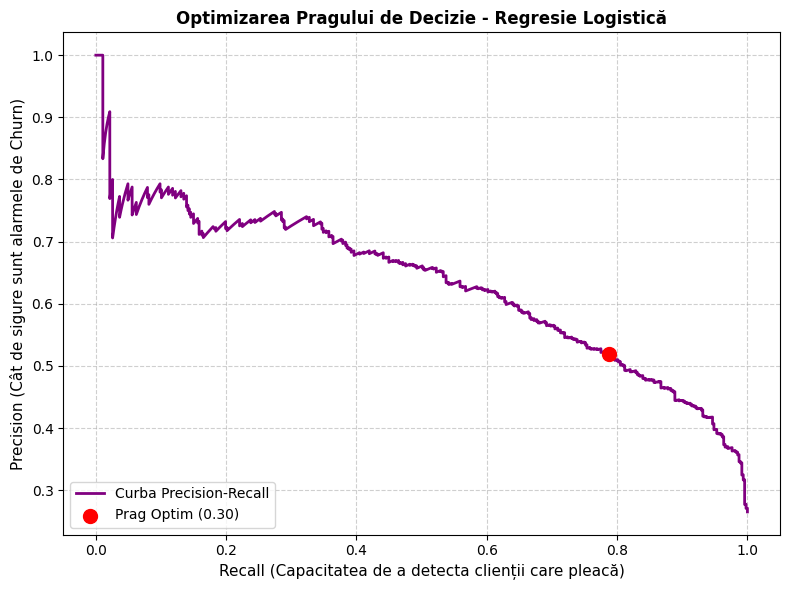

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve, f1_score, classification_report

# ==========================================
# PASUL 4: OPTIMIZARE, ANTRENARE ȘI COMPARAȚIE
# ==========================================

# 1. Optimizare Regresie Logistică cu GridSearchCV (folosește datele scalate)
print("--- 4.1. Optimizare Regresie Logistică ---")
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear']
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=1000),
    param_grid=lr_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
f1_lr = f1_score(y_test, y_pred_lr)

print(f"Cei mai buni parametri Regresie Logistică: {lr_grid.best_params_}")
print(f"F1-score Regresie Logistică optimizată: {f1_lr:.4f}\n")


# 2. Optimizare Random Forest cu GridSearchCV (folosește datele ne-scalate)
print("--- 4.2. Optimizare Random Forest ---")
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=5,
    scoring='f1',  # Folosim F1-score pentru a gestiona mai bine dezechilibrul claselor
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)
f1_rf = f1_score(y_test, y_pred_rf)

print(f"Cei mai buni parametri RF: {rf_grid.best_params_}")
print(f"F1-score RF optimizat: {f1_rf:.4f}\n")


# 3. Optimizare XGBoost cu GridSearchCV (folosește datele ne-scalate)
print("--- 4.3. Optimizare XGBoost ---")
xgb_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}

xgb_grid = GridSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid=xgb_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
xgb_grid.fit(X_train, y_train)

best_xgb = xgb_grid.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
f1_xgb = f1_score(y_test, y_pred_xgb)

print(f"Cei mai buni parametri XGBoost: {xgb_grid.best_params_}")
print(f"F1-score XGBoost optimizat: {f1_xgb:.4f}\n")


# 4. Comparație și Verdict Final
print("=" * 45)
print("🏆 COMPARAȚIE FINALĂ & VERDICT (3 MODELE)")
print("=" * 45)

print(f"F1-score Regresie Logistică optimizată: {f1_lr:.4f}")
print(f"F1-score Random Forest optimizat:       {f1_rf:.4f}")
print(f"F1-score XGBoost optimizat:             {f1_xgb:.4f}")

# Determinăm câștigătorul
scores = {
    "Regresie Logistică": f1_lr,
    "Random Forest": f1_rf,
    "XGBoost": f1_xgb
}
best_model_name = max(scores, key=scores.get)

print(f"\n=> VERDICT: Modelul câștigător este **{best_model_name}** cu un F1-score de {scores[best_model_name]:.4f}.")

print("=" * 50)
print("🎯 6. OPTIMIZAREA PRAGULUI DE DECIZIE (Regresia Logistică)")
print("=" * 50)

# 1. Extragem probabilitățile pentru clasa pozitivă (Churn = 1)
y_probs_lr = best_lr.predict_proba(X_test_scaled)[:, 1]

# 2. Testăm o grilă de praguri de la 0.01 la 0.99
thresholds = np.linspace(0.01, 0.99, 100)
best_threshold = 0.5
best_f1_tuned = 0

for th in thresholds:
    y_pred_th = (y_probs_lr >= th).astype(int)
    score = f1_score(y_test, y_pred_th)
    if score > best_f1_tuned:
        best_f1_tuned = score
        best_threshold = th

print(f"Pragul implicit: 0.50 | F1-score inițial: {f1_lr:.4f}")
print(f"Pragul optim găsit: {best_threshold:.2f} | F1-score optimizat: {best_f1_tuned:.4f}")

# 3. Generăm predicțiile oficiale optimizate pentru Regresia Logistică
y_pred_lr_tuned = (y_probs_lr >= best_threshold).astype(int)

print("=" * 50)
print("📈 VIZUALIZAREA CURBEI PRECISION-RECALL (THRESHOLD TUNING)")
print("=" * 50)

# 1. Calculăm valorile pentru curbă
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs_lr)

# 2. Generarea graficului
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='purple', lw=2, label='Curba Precision-Recall')

# (Opțional) Putem marca pe grafic exact unde se află pragul tău optim
# Căutăm pragul din listă cel mai apropiat de best_threshold găsit anterior
idx_opt = (np.abs(thresholds_pr - best_threshold)).argmin()
plt.scatter(recall[idx_opt], precision[idx_opt], color='red', s=100, zorder=5,
            label=f'Prag Optim ({best_threshold:.2f})')

plt.xlabel('Recall (Capacitatea de a detecta clienții care pleacă)', fontsize=11)
plt.ylabel('Precision (Cât de sigure sunt alarmele de Churn)', fontsize=11)
plt.title('Optimizarea Pragului de Decizie - Regresie Logistică', fontsize=12, fontweight='bold')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Pasul 5 - Evaluare detaliată și matrici de confuzie grafice pentru ambele modele <br>
Evaluăm performanța detaliată a ambelor modele (Random Forest și XGBoost) pe setul de test. Generăm rapoartele de clasificare (Precision, Recall, F1) și reprezentăm grafic matricea de confuzie pentru fiecare în parte, pentru a vizualiza clar performanța pe clasa minoritară (churn).**

📊 5. EVALUARE DETALIATĂ: REGRESIE LOGISTICĂ vs RF vs XGBOOST

--- A. RAPORT CLASIFICARE: Regresie Logistică Optimizată ---
              precision    recall  f1-score   support

No Churn (0)       0.85      0.88      0.87      1294
   Churn (1)       0.64      0.56      0.59       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761


--- B. RAPORT CLASIFICARE: Random Forest Optimizat ---
              precision    recall  f1-score   support

No Churn (0)       0.83      0.91      0.87      1294
   Churn (1)       0.66      0.49      0.56       467

    accuracy                           0.80      1761
   macro avg       0.74      0.70      0.71      1761
weighted avg       0.78      0.80      0.79      1761


--- C. RAPORT CLASIFICARE: XGBoost Optimizat ---
              precision    recall  f1-score   support

No Churn (0)       0.83      0.91      0.87      1294
   Churn

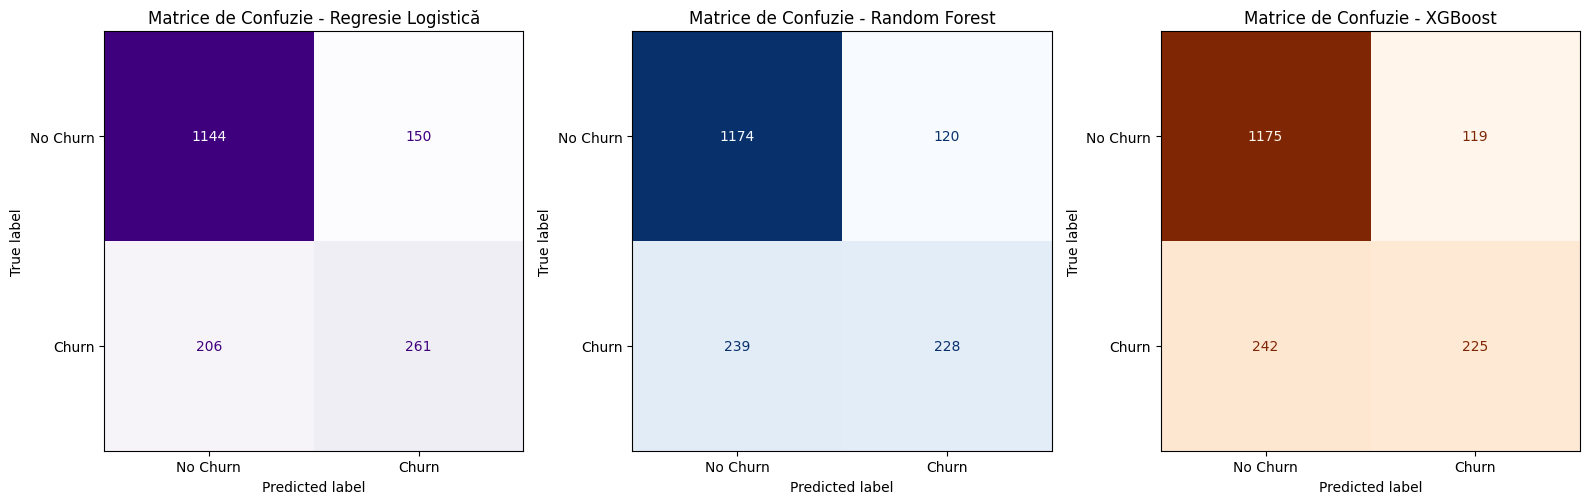

🔍 ANALIZA IMPORTANȚEI CARACTERISTICILOR (Logistic Regression)


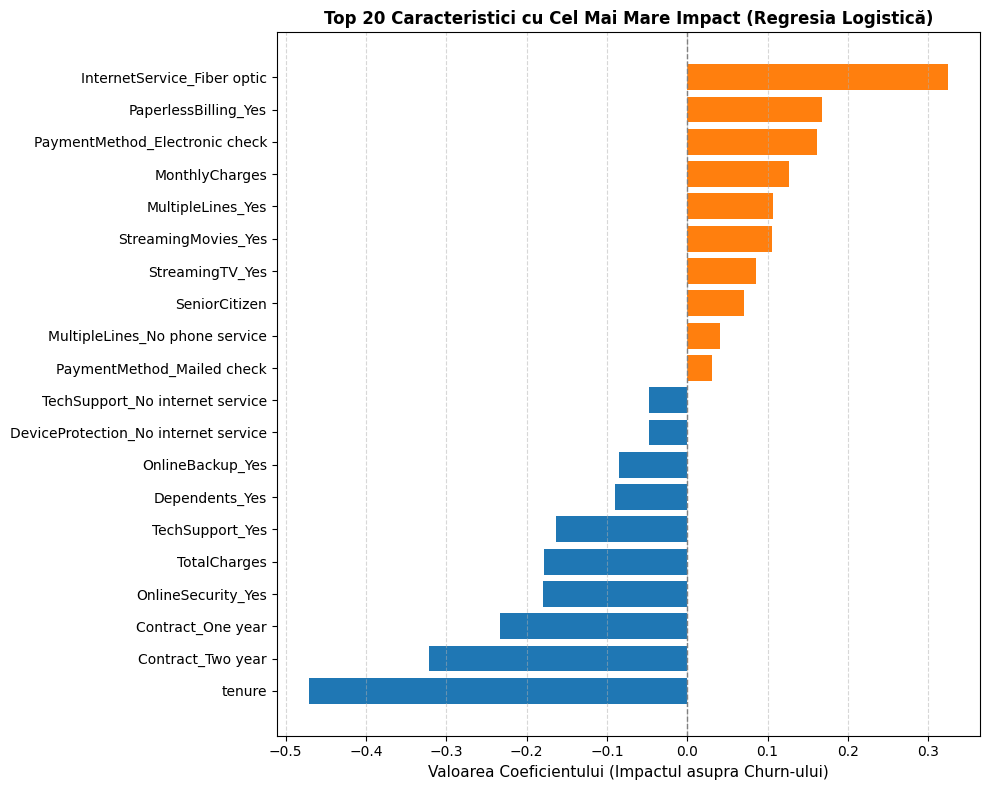

In [31]:
# 5. Evaluare detaliată și matrici grafice pentru cele 3 modele
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("=" * 60)
print("📊 5. EVALUARE DETALIATĂ: REGRESIE LOGISTICĂ vs RF vs XGBOOST")
print("=" * 60)

# --- 1. Rapoarte numerice detaliate ---
print("\n--- A. RAPORT CLASIFICARE: Regresie Logistică Optimizată ---")
print(classification_report(y_test, y_pred_lr, target_names=["No Churn (0)", "Churn (1)"]))

print("\n--- B. RAPORT CLASIFICARE: Random Forest Optimizat ---")
print(classification_report(y_test, y_pred_rf, target_names=["No Churn (0)", "Churn (1)"]))

print("\n--- C. RAPORT CLASIFICARE: XGBoost Optimizat ---")
print(classification_report(y_test, y_pred_xgb, target_names=["No Churn (0)", "Churn (1)"]))

# --- 2. Reprezentare grafică (Matrici de confuzie vizuale pentru toate cele 3 modele) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Grafic Regresie Logistică
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=["No Churn", "Churn"],
    ax=axes[0],
    cmap="Purples",
    colorbar=False
)
axes[0].set_title("Matrice de Confuzie - Regresie Logistică")

# Grafic Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=["No Churn", "Churn"],
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)
axes[1].set_title("Matrice de Confuzie - Random Forest")

# Grafic XGBoost
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_xgb,
    display_labels=["No Churn", "Churn"],
    ax=axes[2],
    cmap="Oranges",
    colorbar=False
)
axes[2].set_title("Matrice de Confuzie - XGBoost")

plt.tight_layout()
plt.show()

print("=" * 50)
print("🔍 ANALIZA IMPORTANȚEI CARACTERISTICILOR (Logistic Regression)")
print("=" * 50)

coefficients = best_lr.coef_[0]
feature_names = X.columns
feat_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feat_importance = feat_importance.sort_values(by='Coefficient', ascending=True)
top_features = pd.concat([feat_importance.head(10), feat_importance.tail(10)])

plt.figure(figsize=(10, 8))
colors = ['tab:blue' if c < 0 else 'tab:orange' for c in top_features['Coefficient']]
plt.barh(top_features['Feature'], top_features['Coefficient'], color=colors)

plt.axvline(x=0, color='grey', linestyle='--', linewidth=1)
plt.xlabel('Valoarea Coeficientului (Impactul asupra Churn-ului)', fontsize=11)
plt.title('Top 20 Caracteristici cu Cel Mai Mare Impact (Regresia Logistică)', fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Pasul 6 - Concluzie, Comparație cu Baseline și Limitare<br>
Analizam rezultatele, comparăm modelul câștigător cu baseline-ul, oferim recomandarea finală și menționăm limitarea analizei.**

In [28]:
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 6. CONCLUZIE ȘI COMPARAȚIE CU BASELINE
# ==========================================
print("\n" + "=" * 50)
print("📌 6. COMPARAȚIE CU BASELINE & RECOMANDARE")
print("=" * 50)

# Colectăm scorurile pentru a afla automat care model a fost cel mai bun
models_performance = {
    "Regresie Logistică": {"acc": accuracy_score(y_test, y_pred_lr), "f1": f1_lr},
    "Random Forest": {"acc": accuracy_score(y_test, y_pred_rf), "f1": f1_rf},
    "XGBoost": {"acc": accuracy_score(y_test, y_pred_xgb), "f1": f1_xgb}
}

best_model_name = max(models_performance, key=lambda k: models_performance[k]["f1"])
best_acc = models_performance[best_model_name]["acc"]
best_f1 = models_performance[best_model_name]["f1"]

# Calculăm metricile pentru baseline
baseline_acc = accuracy_score(y_test, y_pred_dummy)
baseline_f1 = f1_score(y_test, y_pred_dummy, zero_division=0)  # F1 e 0 pentru că baseline-ul nu ghicește clasa minoritară

print(f"1. Model Baseline (DummyClassifier):")
print(f"    - Acuratețe: {baseline_acc:.4f} (~73.4%)")
print(f"    - F1-score (Churn): {baseline_f1:.4f}")
print("    * Notă: Ghicește doar clasa majoritară, ratând complet clienții care pleacă.")

print(f"\n2. Model Câștigător ({best_model_name} Optimizat):")
print(f"    - Acuratețe: {best_acc:.4f}")
print(f"    - F1-score (Churn): {best_f1:.4f}")

print("\n3. CONCLUZIE & LIMITARE:")
print(f"    - Modelul {best_model_name} depășește clar baseline-ul pe F1-score, reușind să detecteze eficient clienții cu risc de churn.")
print("    - Limitare: Dezechilibrul nativ al claselor (~26% churn) limitează performanța maximă, lipsind tehnici avansate precum SMOTE sau ajustarea pragurilor de decizie.")


📌 6. COMPARAȚIE CU BASELINE & RECOMANDARE
1. Model Baseline (DummyClassifier):
    - Acuratețe: 0.7348 (~73.4%)
    - F1-score (Churn): 0.0000
    * Notă: Ghicește doar clasa majoritară, ratând complet clienții care pleacă.

2. Model Câștigător (Regresie Logistică Optimizat):
    - Acuratețe: 0.7978
    - F1-score (Churn): 0.5945

3. CONCLUZIE & LIMITARE:
    - Modelul Regresie Logistică depășește clar baseline-ul pe F1-score, reușind să detecteze eficient clienții cu risc de churn.
    - Limitare: Dezechilibrul nativ al claselor (~26% churn) limitează performanța maximă, lipsind tehnici avansate precum SMOTE sau ajustarea pragurilor de decizie.
